<a href="https://colab.research.google.com/github/SHINXkeshi/Lab7_Intro_to_ML_SANTAMARIA/blob/main/Lab7_Intro_to_ML_SANTAMARIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 7: Supervised vc. Unsupervised Learning, Overfitting, and Cross-Validation

## Fundamentals of Artificial Intelligence

**Name:** Sebastian B. Santamaria
**Course:** ELFUNDAI
**Section** BSCSAI-2
**Date:** October 20,2026

**Dataset Source (GitHub raw URL):**

https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:**

## Description
This laboratory compares supervised and unsupervised learning, demonstrates overfitting and underfitting through a complexity sweep, and evaluates models using k-fold cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    adjusted_rand_score,
)

GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df["species"].value_counts())

feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Training samples: (105, 4)
Testing samples: (45, 4)


## Part A: Supervised Learning (Lables ARE Used)

The model learns a mapping from features to known labels.
Scaling is placed INSIDE the pipeline so that each cross-validation fold computes scaling statistics from its training portion only.
This prevents data leakage.

In [2]:
supervised_pipeline = Pipeline ([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(max_depth=3, random_state=42))
])

supervised_pipeline.fit(X_train, y_train)

supervised_predictions = supervised_pipeline.predict(X_test)

print("SUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Test accuracy:", accuracy_score (y_test, supervised_predictions))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, supervised_predictions))
print()
print(classification_report(y_test, supervised_predictions))

SUPERVISED LEARNING RESULTS
Test accuracy: 0.9777777777777777

Confusion Matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## Part B: Unsupervised Learning (Labels ARE NOT Used)

The species column completely ignored,
K-Means must discover group structure on its own.
Afterwards, we compare the discovered clusters to the true labels only for evaluation purposes.

UNSUPERVISED LEARNING RESULTS
Cluster vs. True Species crosstab:
True Species        setosa  versicolor  virginica
Discovered Cluster                               
0                        0          48         14
1                       50           0          0
2                        0           2         36

Adjusted Rand Index (cluster agreement with true labels):
0.7302382722834697


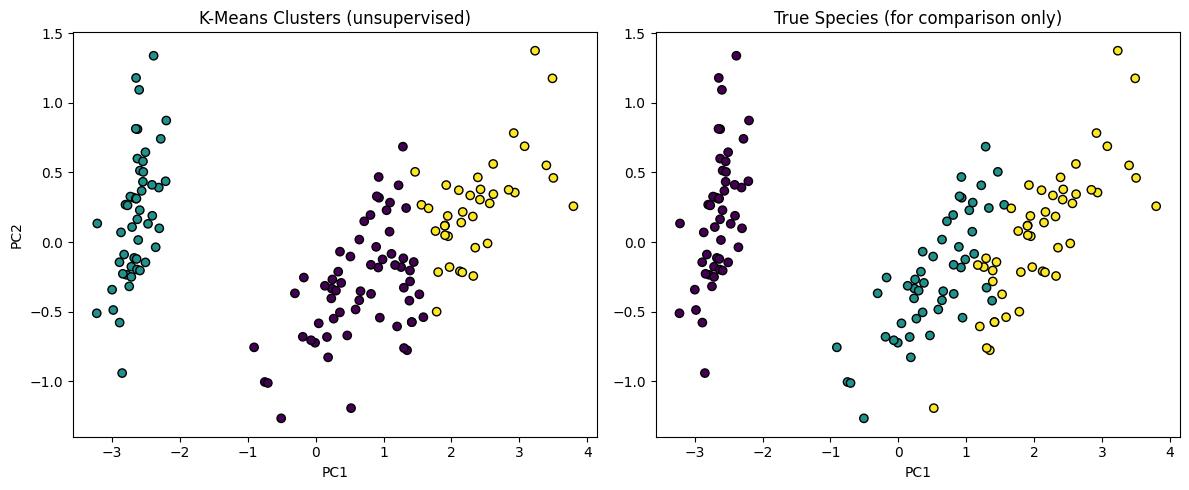

Explained variance ratio: [0.92461872 0.05306648]


In [3]:
# NOTE: y is NOT used anywhere in this part.
X_unlabeled = df[feature_columns].values

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_unlabeled)

comparison = pd.crosstab(
    pd.Series(cluster_labels, name="Discovered Cluster"),
    pd.Series(y, name="True Species")
)

print("UNSUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Cluster vs. True Species crosstab:")
print(comparison)
print()
print("Adjusted Rand Index (cluster agreement with true labels):")
print(adjusted_rand_score(y, cluster_labels))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_unlabeled)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="viridis", edgecolor="k")
plt.title("K-Means Clusters (unsupervised)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
species_codes = pd.factorize(y)[0]
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=species_codes, cmap="viridis", edgecolor="k")
plt.title("True Species (for comparison only)")
plt.xlabel("PC1")

plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

## Part C: Complexity Sweep (Bias_Variance Demonstration)

We train decision trees with increasing max_depth.

- Very small depth -> high bias -> underfitting
- Moderate depth -> sweet spot -> good generalization
-Vey large depth -> high variance -> overfitting (train = 100%, gap widens)

 max_depth  train_accuracy  test_accuracy      gap
         1        0.666667       0.666667 0.000000
         2        0.971429       0.888889 0.082540
         3        0.980952       0.977778 0.003175
         4        0.990476       0.888889 0.101587
         5        1.000000       0.911111 0.088889
         6        1.000000       0.911111 0.088889
         7        1.000000       0.911111 0.088889
         8        1.000000       0.911111 0.088889
         9        1.000000       0.911111 0.088889
        10        1.000000       0.911111 0.088889
        11        1.000000       0.911111 0.088889
        12        1.000000       0.911111 0.088889
        13        1.000000       0.911111 0.088889
        14        1.000000       0.911111 0.088889
        15        1.000000       0.911111 0.088889


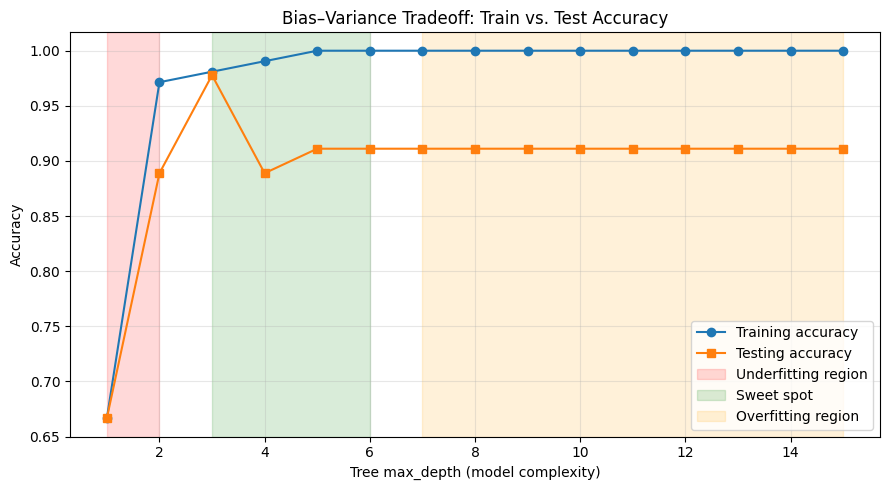

In [4]:
depth_values = list(range(1, 16))

train_scores = []
test_scores = []

for depth in depth_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])

    pipe.fit(X_train, y_train)

    train_scores.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_scores.append(accuracy_score(y_test, pipe.predict(X_test)))

sweep_table = pd.DataFrame({
    "max_depth": depth_values,
    "train_accuracy": train_scores,
    "test_accuracy": test_scores,
    "gap": np.array(train_scores) - np.array(test_scores)
})

print(sweep_table.to_string(index=False))

plt.figure(figsize=(9, 5))

plt.plot(depth_values, train_scores, marker="o", label="Training accuracy")
plt.plot(depth_values, test_scores, marker="s", label="Testing accuracy")

plt.axvspan(1, 2, alpha=0.15, color="red", label="Underfitting region")
plt.axvspan(3, 6, alpha=0.15, color="green", label="Sweet spot")
plt.axvspan(7, 15, alpha=0.15, color="orange", label="Overfitting region")

plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("Accuracy")
plt.title("Bias–Variance Tradeoff: Train vs. Test Accuracy")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observed Regions (fill from your sweep table)

- Underfitting depth(s): [e.g., 1-2], because train and test accuracy are both low.
- Sweet-spot depth(s): [e.g., 3-6], because test accuracy is highest and the gap is small.
- Overfitting depth(s): [e.g., 8-15], because train accuracy reaches 1.0 while the train↔test gap widens.

## Part D: 5-Fold Stratified Cross-Validation

Cross-validation is run ONLY on the training set.
The held-out test set is never used for model selection.
Mean ± standard deviation shows both performance and stability.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Shallow tree (depth=1, high bias)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=1, random_state=42))
    ]),
    "Moderate tree (depth=4)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=42))
    ]),
    "Full tree (no depth limit, high variance)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=None, random_state=42))
    ]),
}

cv_results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results.append({
        "Model": name,
        "CV mean": scores.mean(),
        "CV std": scores.std(),
        "Fold scores": np.round(scores, 3)
    })

    print(name)
    print("  Fold scores:", np.round(scores, 3))
    print(f"  Mean ± std : {scores.mean():.3f} ± {scores.std():.3f}")
    print("-" * 60)

cv_table = pd.DataFrame(cv_results)
print(cv_table.to_string(index=False))

Shallow tree (depth=1, high bias)
  Fold scores: [0.667 0.667 0.667 0.667 0.667]
  Mean ± std : 0.667 ± 0.000
------------------------------------------------------------
Moderate tree (depth=4)
  Fold scores: [0.905 0.952 0.905 0.952 0.952]
  Mean ± std : 0.933 ± 0.023
------------------------------------------------------------
Full tree (no depth limit, high variance)
  Fold scores: [0.905 0.952 0.905 0.952 0.952]
  Mean ± std : 0.933 ± 0.023
------------------------------------------------------------
                                    Model  CV mean   CV std                         Fold scores
        Shallow tree (depth=1, high bias) 0.666667 0.000000 [0.667, 0.667, 0.667, 0.667, 0.667]
                  Moderate tree (depth=4) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]
Full tree (no depth limit, high variance) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]


## ⚠ Data Leakage Demonstration (DO NOT use in real projects)

Below, scaling is fitted on ALL data (including the test set) BEFORE
cross-validation. This leaks test information into training and usually
produces optimistically biased scores. Compare with the pipeline results above.

In [6]:
leaky_scaler = StandardScaler().fit(X)          # WRONG: uses test data too
X_leaky = leaky_scaler.transform(X)

leaky_model = DecisionTreeClassifier(max_depth=4, random_state=42)

leaky_scores = cross_val_score(leaky_model, X_leaky, y, cv=cv, scoring="accuracy")

print("Leaky CV mean:", leaky_scores.mean())
print("Difference vs honest pipeline is usually small on this easy dataset,")
print("but on harder datasets leakage inflates scores dangerously.")


Leaky CV mean: 0.9533333333333335
Difference vs honest pipeline is usually small on this easy dataset,
but on harder datasets leakage inflates scores dangerously.


## Guide Questions and Answers

### 1. Which part of this laboratory used supervised learning, and which used unsupervised learning?

**Answer:**
Supervised: the decision tree classification, since the species labels (y) were used in training and in the stratified split, evaluation, and cross-validation. Unsupervised: K-Means clustering, since it used only the features and no labels.

### 2. Did the K-Means clusters match the true species? Explain using the crosstab and Adjusted Rand Index.

**Answer:**
Partly. Setosa usually forms its own clean cluster, while versicolor and virginica overlap and get mixed in the crosstab. An ARI near 1 means the clusters match the species, and a value near 0 means they match no better than random. Because K-Means never saw the labels, it finds structure, not "correct" answers. Fill in your own ARI value: [ARI = ___].

### 3. Which max_depth value(s) showed underfitting? What evidence supports this?

**Answer:**
The very shallow depths (e.g., max_depth = 1, [confirm from your sweep]). Both train and test accuracy were low and close together, so the tree was too simple to capture the pattern (high bias).

### 4. Which max_depth value(s) showed overfitting? What evidence supports this?

**Answer:**
The large depths (e.g., [your depths]). Train accuracy was near 100% while test accuracy was lower, and the train-test gap widened (high variance).

### 5. Why does training accuracy reach 100% at large depths?

**Answer:**
A deep tree has enough complexity to memorize every training sample, including noise, by splitting until each leaf is pure. It fits the training data perfectly but fails to generalize.

### 6. What do the CV mean and CV standard deviation tell you about a model?

**Answer:**
The CV mean is the model's average expected performance across folds. The standard deviation shows how stable that performance is. A large standard deviation means the score depends heavily on which data lands in each fold.

### 7. Why must StandardScaler be placed inside the Pipeline?

**Answer:**
 So the scaler is fitted only on the training folds in each CV round. Scaling the whole dataset first leaks validation/test statistics into training (data leakage), which inflates the scores.

### 8. Connect your sweep curve to bias and variance.

**Answer:**
At low depth, bias is high and variance is low, so the model underfits. At high depth, bias is low and variance is high, so the model overfits. The best test and CV accuracy sits in the middle depth (the sweet spot), where total error is lowest.


## Reflection

### Challenges Encountered
- Understanding why K-Means clusters do not perfectly match the true species.
- Identifying the underfitting and overfitting depths from the train/test curves.
- Understanding how to keep preprocessing inside the Pipeline to avoid data leakage.

### What I Learned
- Supervised learning uses labels to predict outputs, while unsupervised learning discovers structure without labels.
- Memorizing the training data is not learning. Generalization to unseen data is the goal.
- Underfitting means high bias, and overfitting means high variance.
- Cross-validation gives a more reliable estimate than a single split, and the final test set must be touched only once.
- Data leakage makes results look better than they really are, and Pipelines prevent it.